# Multiple Origins and frames / 複数のOriginと座標系

Use a two-link planar arm to compare the fixed World frame, the shoulder frame, and the elbow frame.  
2リンク平面アームを使い、固定されたWorld座標系、肩ローカル座標系、肘ローカル座標系を比較します。

## Learning goals / 学習目標

- An Origin does not have to be unique in the world. / Originは世界に1つしかないわけではありません。
- A local coordinate frame can be placed at each joint. / 各関節ごとにローカル座標系を置けます。
- The elbow is always `(0, 0)` in its own elbow frame. / 肘は肘ローカル座標系では常に`(0, 0)`です。
- The elbow Origin's World position changes with the shoulder angle. / Worldから見た肘Originの位置は肩角度によって変わります。
- Rotating the shoulder moves and rotates the complete elbow frame. / 肩を回すと、肘位置だけでなく肘ローカル座標系全体が移動・回転します。
- `theta2` is relative to the upper arm. / 肘角度`theta2`は上腕に対する相対角度です。
- The forearm's absolute World angle is `theta1 + theta2`. / Worldから見た前腕の絶対角度は`theta1 + theta2`です。
- Two-link forward kinematics adds the World vectors shoulder → elbow and elbow → wrist. / 2リンク順運動学は、World座標で表した「肩→肘」と「肘→手首」を足し合わせます。

## Mathematics / 数学

The shoulder is fixed at the World Origin. / 肩はWorld Originに固定します。

$$x_{elbow}=L_1\cos(\theta_1), \qquad y_{elbow}=L_1\sin(\theta_1)$$

Because `theta2` is relative to link 1, the forearm uses `theta1 + theta2` in World.  
`theta2`は第1リンクに対する相対角度なので、World上の前腕には`theta1 + theta2`を使います。

$$x_{wrist}=L_1\cos(\theta_1)+L_2\cos(\theta_1+\theta_2)$$

$$y_{wrist}=L_1\sin(\theta_1)+L_2\sin(\theta_1+\theta_2)$$

## Interactive backend / 対話的バックエンド

Install the optional dependencies with `python -m pip install -e ".[notebook]"`. Classic Notebook users can try `%matplotlib notebook`.  
追加依存関係は`python -m pip install -e ".[notebook]"`で導入できます。Classic Notebookでは`%matplotlib notebook`も使用できます。

In [1]:
%matplotlib widget

from robotics_math_study import forward_kinematics_2link
from robotics_math_study.two_link_frames import TwoLinkFrameVisualizer

## Numerical calculation without drawing / 描画から独立した数値計算

The function returns all joint positions in World coordinates. The elbow-local Origin is separately defined as `(0, 0)`.  
関数は各関節位置をWorld座標で返します。肘ローカル座標系のOriginは、これとは別に常に`(0, 0)`と定義されます。

In [2]:
pose = forward_kinematics_2link(
    link_length_1=5.0,
    link_length_2=4.0,
    theta_1_deg=30.0,
    theta_2_deg=45.0,
)
pose

{'shoulder_world': (0.0, 0.0),
 'elbow_world': (4.330127018922194, 2.4999999999999996),
 'wrist_world': (5.365403199332277, 6.363703305156273),
 'shoulder_angle_world_deg': 30.0,
 'forearm_angle_world_deg': 75.0}

## Interactive visualization / 対話的可視化

Move the two Sliders and compare the two lines displayed at the elbow: **Elbow local: (0,0)** and **Elbow in World: (x,y)**.  
2本のSliderを動かし、肘に表示される **Elbow local: (0,0)** と **Elbow in World: (x,y)** を比較してください。

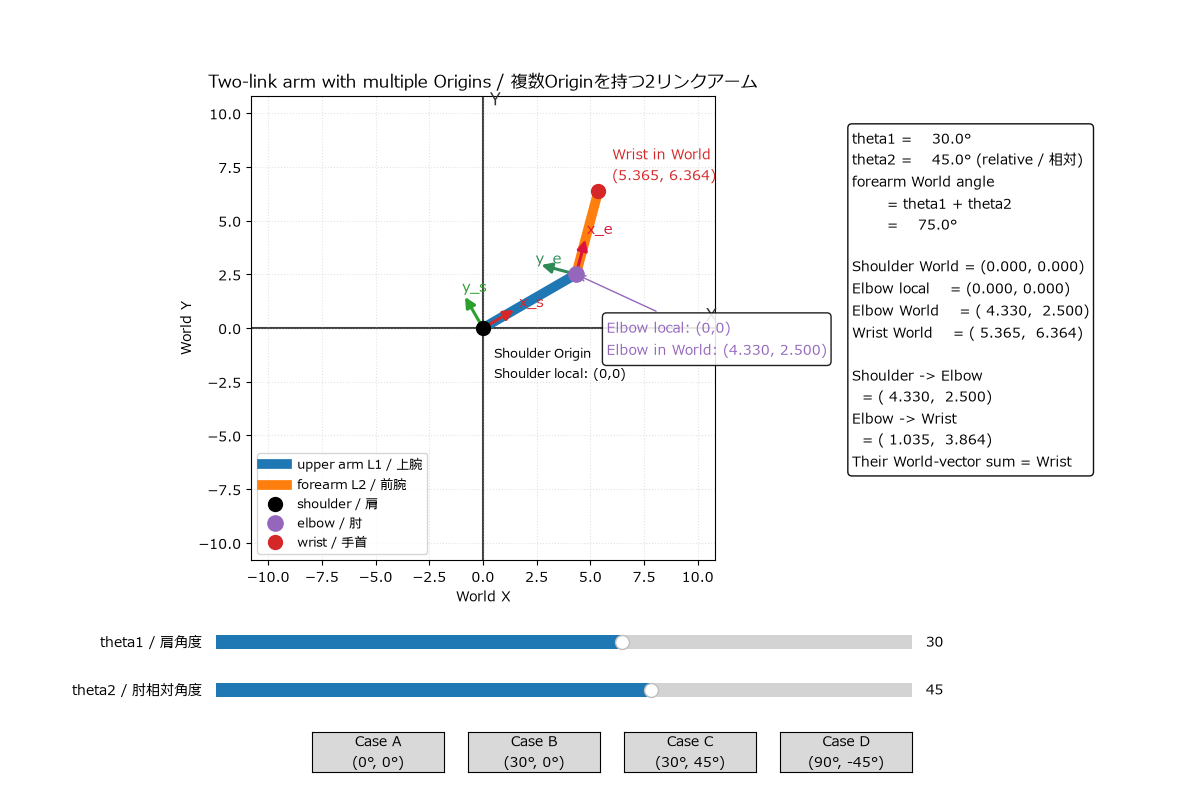

In [4]:
visualizer = TwoLinkFrameVisualizer(
    link_length_1=5.0,
    link_length_2=4.0,
    initial_theta_1_deg=30.0,
    initial_theta_2_deg=45.0,
)
visualizer.show()

### Reference cases / 代表ケース

Use the buttons or call one of these methods. / ボタンまたは次のメソッドを使います。

- Case A: `visualizer.set_case("A")` → `(theta1, theta2) = (0°, 0°)`
- Case B: `visualizer.set_case("B")` → `(theta1, theta2) = (30°, 0°)`
- Case C: `visualizer.set_case("C")` → `(theta1, theta2) = (30°, 45°)`
- Case D: `visualizer.set_case("D")` → `(theta1, theta2) = (90°, -45°)`

In [5]:
visualizer.set_case("C")

## Questions / 確認問題

**Q1.** When `theta1` changes, does the elbow's coordinate in the elbow-local frame change?  
`theta1`を変えたとき、肘ローカル座標系における肘自身の座標は変わるか？

**Q2.** When `theta1` changes, does the elbow's coordinate in the World frame change?  
`theta1`を変えたとき、World座標系における肘の座標は変わるか？

**Q3.** For `theta1=30°`, `theta2=45°`, what is the forearm direction seen from World?  
`theta1=30°`, `theta2=45°`のとき、Worldから見た前腕の向きは何度か？

**Q4.** Why is the wrist position the sum of the shoulder→elbow and elbow→wrist vectors?  
なぜ手首位置は「肩→肘」と「肘→手首」の2つのベクトルの和で求まるのか？

<details>
<summary><strong>Answer / 解答例</strong></summary>

1. No. The elbow is the Origin of its own frame, so it always remains `(0,0)`. / 変わりません。肘自身が肘フレームのOriginなので、常に`(0,0)`です。
2. Yes. Its World coordinate is `(L1*cos(theta1), L1*sin(theta1))`. / 変わります。World座標は`(L1*cos(theta1), L1*sin(theta1))`です。
3. `30° + 45° = 75°`. `theta2` is relative to link 1. / `30° + 45° = 75°`です。`theta2`は第1リンクに対する相対角度です。
4. Both vectors are expressed in the same World frame and connected head-to-tail, so their sum reaches from the shoulder to the wrist. / 2つのベクトルを同じWorld座標系で表し、先端同士をつなぐと、和が肩から手首へ到達するベクトルになるためです。

</details>

## Explain it in your own words / 自分の言葉で説明する

Fill in the blanks without reopening the answer. / 解答を閉じたまま穴埋めしてください。

「肘は、肘ローカル座標系では **________** だが、World座標系では **________** によって位置が変わる。」

「2リンクアームでは、第2リンクのWorld上の向きは **________ + ________** で表される。」